## Wstęp do Uczenia Maszynowego

#### Laboratorium 07


### Zakres laboratorium

- regularyzacja Elastic Net w regresji logistycznej (z wykorzystaniem `Pipeline` i `ColumnTransformer` z lab06)
- maszyny wektorów podpierających (SVM)
- margines, wektory podpierające i parametr `C`
- dobór parametru `C` metodą GridSearchCV


In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
import sklearn.model_selection as skm

### 1. Regresja logistyczna z regularyzacją Elastic Net

Elastic Net łączy kary L1 i L2 w jednej funkcji kosztu:

$$
\mathcal{L}(\boldsymbol{\beta})
= -\frac{1}{n} \sum_{i=1}^{n}
\Big[
y_i \log(p_i) + (1 - y_i) \log(1 - p_i)
\Big]
+ \lambda \left(
\alpha \|\boldsymbol{\beta}\|_1 +
\frac{1 - \alpha}{2} \|\boldsymbol{\beta}\|_2^2
\right).
$$

Parametr $\alpha \in [0, 1]$ określa udział kary L1: dla $\alpha=1$ otrzymujemy Lasso, dla $\alpha=0$ Ridge, a dla wartości pośrednich — Elastic Net. W `scikit-learn` odpowiada mu parametr `l1_ratio`.


---
##### *Zadanie 1*

Na danych `credit-g`:

 a) Wczytaj dane, wybierz zmienne `age`, `existing_credits`, `duration`, `credit_amount`, `savings_status` i `credit_history`, a klasę `good` zakoduj jako 1.

 b) Podziel dane na zbiory treningowy i testowy. Przygotowanie danych połącz z modelem w `Pipeline`, tak jak w lab06: `ColumnTransformer` powinien standaryzować zmienne numeryczne (`StandardScaler`) i kodować zmienne kategoryczne (`OneHotEncoder`).

 c) Dla każdej wartości
$$C \in \{0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10, 50, 100\}$$
oceń pipeline z regresją logistyczną z karą L1 za pomocą 5-krotnej walidacji krzyżowej na zbiorze treningowym (`cross_val_score`, miara `roc_auc`). Wyznacz też liczbę niezerowych współczynników modelu dopasowanego do całego zbioru treningowego. Jak zmienia się liczba niezerowych współczynników wraz ze wzrostem `C`? Dlaczego dla najmniejszych wartości `C` AUC wynosi 0.5?

 d) Ustal `C = 0.1` i w ten sam sposób porównaj modele Elastic Net dla różnych wartości `l1_ratio`. Wybierz `l1_ratio`, uzasadnij wybór, a następnie dopasuj wybrany model do całego zbioru treningowego i raz oceń AUC na zbiorze testowym.

Dzięki `Pipeline` skaler i koder są w każdym foldzie dopasowywane wyłącznie do jego części uczącej, więc ani fold walidacyjny, ani zbiór testowy nie wpływają na przygotowanie danych.

> W starszej wersji `scikit-learn` należy w funkcji `LogisticRegression()` ustawić parametr `penalty`, na wartość "l1", "l2" lub "elasticnet". Parametr `l1_ratio` służy tylko do ustawiania wartości $\alpha$.


In [41]:
# Wczytanie danych i wybór zmiennych.
credit = fetch_openml(name='credit-g', version=1, as_frame=True)
df = credit.frame
sel_cols = ['age', 'existing_credits', 'duration', 'credit_amount',
            'savings_status', 'credit_history', 'class']
df = df[sel_cols].copy()

In [ ]:
# Kodowanie klasy i podział danych.
df['class'] = (df['class'] == 'good').astype(int)
X = df.drop(columns='class')
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

numerical_features = ['age', 'existing_credits', 'duration', 'credit_amount']
categorical_features = ['savings_status', 'credit_history']


def make_model(C, l1_ratio):
    """Pipeline: standaryzacja cech numerycznych, one-hot dla kategorycznych i regresja logistyczna."""
    preprocessor = ColumnTransformer([
        ('numerical', StandardScaler(), numerical_features),
        ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ('pre', preprocessor),
        ('clf', LogisticRegression(
            solver='saga', l1_ratio=l1_ratio, C=C,
            max_iter=5000, tol=1e-6, random_state=42,
        )),
    ])


# starsza wersja scikit-learn
# def make_model_old(C, l1_ratio, penalty):
#     """Pipeline: standaryzacja cech numerycznych, one-hot dla kategorycznych i regresja logistyczna."""
#     preprocessor = ColumnTransformer([
#         ('numerical', StandardScaler(), numerical_features),
#         ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
#     ], verbose_feature_names_out=False)
#     return Pipeline([
#         ('pre', preprocessor),
#         ('clf', LogisticRegression(
#             solver='saga', l1_ratio=l1_ratio, penalty = penalty, C=C,
#             max_iter=5000, tol=1e-6, random_state=42,
#         )),
#     ])

In [ ]:
# Warstwowa walidacja krzyżowa na zbiorze treningowym (zbiór testowy pozostaje nietknięty).
cv = skm.StratifiedKFold(5, shuffle=True, random_state=42)


def evaluate(C, l1_ratio):
    """Średnie AUC z walidacji krzyżowej i liczba niezerowych współczynników modelu dopasowanego do całego X_train."""
    model = make_model(C=C, l1_ratio=l1_ratio)
    # w każdym foldzie pipeline dopasowuje skaler i koder wyłącznie do części uczącej
    auc_cv = skm.cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    model.fit(X_train, y_train)
    return {'C': C, 'l1_ratio': l1_ratio,
            'AUC_cv_mean': auc_cv.mean(), 'AUC_cv_std': auc_cv.std(),
            'nonzero_coef': np.count_nonzero(model['clf'].coef_)}

# starsza wersja scikit-learn
# def evaluate_old(C, l1_ratio, penalty):
#     """Średnie AUC z walidacji krzyżowej i liczba niezerowych współczynników modelu dopasowanego do całego X_train."""
#     model = make_model_old(C=C, l1_ratio=l1_ratio, penalty=penalty)
#     # w każdym foldzie pipeline dopasowuje skaler i koder wyłącznie do części uczącej
#     auc_cv = skm.cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
#     model.fit(X_train, y_train)
#     return {'C': C, 'l1_ratio': l1_ratio,
#             'AUC_cv_mean': auc_cv.mean(), 'AUC_cv_std': auc_cv.std(),
#             'nonzero_coef': np.count_nonzero(model['clf'].coef_)}


C_values = [0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10, 50, 100]
pd.DataFrame([evaluate(C=C, l1_ratio=None) for C in C_values])

# starsza wersja scikit-learn
# pd.DataFrame([evaluate_old(C=C, l1_ratio=None, penalty="l1") for C in C_values])

,C,l1_ratio,AUC_cv_mean,AUC_cv_std,nonzero_coef
0,0.001,None,0.500000,0.000000,0
1,0.010,None,0.500000,0.000000,0
2,0.100,None,0.692489,0.067759,5
3,0.500,None,0.705435,0.052434,12
4,1.000,None,0.708816,0.053379,11
5,2.000,None,0.712058,0.052493,11
6,5.000,None,0.714145,0.053452,12
7,10.000,None,0.714678,0.052539,12
8,50.000,None,0.715211,0.052698,12
9,100.000,None,0.715259,0.052591,12


**Odpowiedź.** Wraz ze wzrostem `C` regularyzacja słabnie (`C` jest odwrotnością siły kary), więc kara L1 zeruje coraz mniej współczynników i liczba niezerowych współczynników rośnie. Dla najmniejszych wartości `C` kara jest tak silna, że wszystkie współczynniki są zerowe — model zwraca dla każdej obserwacji to samo prawdopodobieństwo (wynikające tylko z wyrazu wolnego, który nie jest karany). Stała predykcja nie rozróżnia klas, więc AUC wynosi 0.5.


In [ ]:
# Parametr alpha z równania (l1_ratio w sklearn) przy ustalonym C = 0.1.
alphas = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]
pd.DataFrame([evaluate(C=0.1, l1_ratio=alpha) for alpha in alphas])

# starsza wersja scikit-learn
# pd.DataFrame([evaluate_old(C=0.1, l1_ratio=alpha, penalty="elasticnet") for alpha in alphas])

,C,l1_ratio,AUC_cv_mean,AUC_cv_std,nonzero_coef
0,0.1,0.00,0.707121,0.062516,12
1,0.1,0.10,0.706151,0.062152,11
2,0.1,0.25,0.703964,0.061125,11
3,0.1,0.50,0.699990,0.063705,7
4,0.1,0.75,0.694832,0.067268,6
5,0.1,0.90,0.693659,0.066683,5
6,0.1,1.00,0.692489,0.067759,5


**Odpowiedź.** Wraz ze wzrostem `l1_ratio` rośnie udział kary L1, więc coraz więcej współczynników jest zerowanych (od 12 dla Ridge do 5 dla Lasso), a średnie AUC nieznacznie spada. Różnice AUC są jednak mniejsze niż odchylenie standardowe między foldami. Rozsądnym kompromisem jest np. `l1_ratio = 0.5`: model ma tylko 7 niezerowych współczynników, a jego AUC jest porównywalne z modelem Ridge.


In [ ]:
# Ostateczne dopasowanie na całym zbiorze treningowym i jedna ocena na teście.
final_en = make_model(C=0.1, l1_ratio=0.5)

# starsza wersja scikit-learn
# final_en = make_model_old(C=0.1, l1_ratio=0.5, penalty="elasticnet")

final_en.fit(X_train, y_train)
print(f'AUC wybranego Elastic Net na teście: '
      f'{roc_auc_score(y_test, final_en.predict_proba(X_test)[:, 1]):.3f}')

AUC wybranego Elastic Net na teście: 0.677


### 2. Maszyny wektorów podpierających (SVM)


Gdy klasy da się rozdzielić prostą (w ogólności: hiperpłaszczyzną) $\langle w, x\rangle + b = 0$, takich prostych jest zazwyczaj nieskończenie wiele (rysunek poniżej, po lewej). **Klasyfikator maksymalnego marginesu** wybiera tę, która jest najdalej od najbliższych obserwacji obu klas (po prawej). Odległość od prostej do tych obserwacji nazywamy **marginesem**, a obserwacje leżące na granicy marginesu — **wektorami podpierającymi**. Tylko one wyznaczają położenie prostej: przesunięcie pozostałych punktów (bez przekraczania marginesu) nie zmienia modelu.

![](svm_1.png)

W praktyce klasy rzadko są idealnie rozdzielne, dlatego SVM dopuszcza naruszenia marginesu, wprowadzając zmienne $\xi_i \ge 0$. W `scikit-learn` (`SVC`) rozwiązywane jest zadanie

$$
\min_{w,\, b,\, \xi}\ \frac{1}{2}\|w\|^2 + C \sum_{i=1}^{n} \xi_i
\quad \text{przy warunkach} \quad
y_i\left(\langle w, x_i\rangle + b\right) \ge 1 - \xi_i,\quad \xi_i \ge 0,
$$

gdzie $y_i \in \{-1, 1\}$. Granice marginesu to proste $\langle w, x\rangle + b = \pm 1$, odległe od prostej rozdzielającej o $\frac{1}{\|w\|}$. Wektorami podpierającymi są teraz wszystkie obserwacje leżące na granicy marginesu, wewnątrz niego lub po złej stronie prostej.

Parametr `C` to **kara za naruszenia marginesu**:
- duże `C` — naruszenia są kosztowne, margines jest wąski, mało wektorów podpierających (ryzyko przeuczenia);
- małe `C` — naruszenia są tanie, margines jest szeroki, wiele wektorów podpierających (większe obciążenie, mniejsza wariancja).


Do rysowania dopasowanych modeli wykorzystamy pomocniczą funkcję `plot_svm_2d`.


In [46]:
# Uproszczona adaptacja ISLP.svm.plot, umieszczona lokalnie, aby uniknąć
# instalowania pakietu ISLP wraz z rozbudowanymi zależnościami.
# Źródło: https://github.com/intro-stat-learning/ISLP/blob/main/ISLP/svm.py
def plot_svm_2d(X, y, model, ax=None, grid_size=300):
    """Rysuje obszary decyzyjne, margines i wektory podpierające liniowego SVM."""
    X = np.asarray(X)
    y = np.asarray(y)
    if X.ndim != 2 or X.shape[1] != 2:
        raise ValueError("Funkcja wymaga danych z dokładnie dwiema zmiennymi.")

    if ax is None:
        _, ax = plt.subplots()

    x0, x1 = X[:, 0], X[:, 1]
    xlim = (x0.min() - 0.5 * x0.std(), x0.max() + 0.5 * x0.std())
    ylim = (x1.min() - 0.5 * x1.std(), x1.max() + 0.5 * x1.std())
    xx, yy = np.meshgrid(
        np.linspace(*xlim, grid_size), np.linspace(*ylim, grid_size)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    ax.scatter(x0, x1, c=y, cmap=plt.cm.tab10, s=200)
    ax.contourf(
        xx, yy, model.predict(grid).reshape(xx.shape),
        cmap=plt.cm.plasma, alpha=0.2
    )
    decision = model.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, decision, levels=[-1, 1], cmap=plt.cm.plasma, alpha=0.2)
    support_idx = model.support_
    support_decision = model.decision_function(X[support_idx])
    signed_y = np.where(y[support_idx] == model.classes_[1], 1, -1)
    correctly_classified = signed_y * support_decision > 0
    ax.scatter(
        X[support_idx, 0][correctly_classified],
        X[support_idx, 1][correctly_classified],
        marker="+", c="black", s=80, linewidths=1.5
    )
    ax.scatter(
        X[support_idx, 0][~correctly_classified],
        X[support_idx, 1][~correctly_classified],
        marker="x", c="red", s=80, linewidths=1.5
    )
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    return ax

In [47]:
# losowanie dwóch zmiennych z rozkładu standardowego normalnego
rng = np.random.default_rng(1)
X = rng.standard_normal((50,2))
y = np.array([-1]*25 + [1]*25)
# przesunięcie punktów o wektor [2, 2]
X[y == 1] += 2

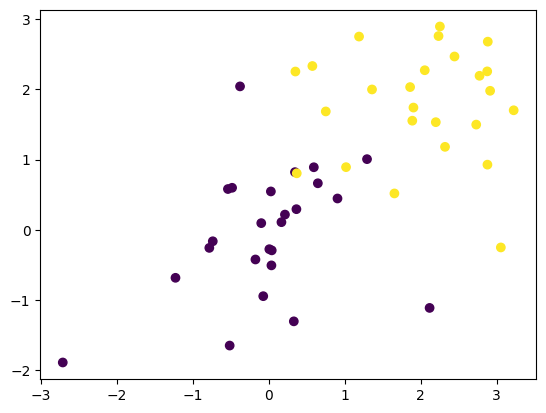

In [48]:
# wykres punktów
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

-----
##### *Zadanie 2*

Zbuduj model wektorów podpierających, wykorzystując zdefiniowane `X` i `y` jako zbiór treningowy. Ustaw parametr `C = 10` oraz `kernel = 'linear'`. Narysuj dopasowany model funkcją `plot_svm_2d`.


**Jak czytać wykres `plot_svm_2d`:**
- kolor tła — obszar decyzyjny, czyli klasa, którą model przypisuje punktom z danego obszaru;
- ciemniejszy pas wzdłuż granicy — margines, czyli obszar między prostymi $\langle w, x\rangle + b = -1$ i $\langle w, x\rangle + b = 1$;
- `+` — wektor podpierający sklasyfikowany poprawnie, ale leżący na granicy marginesu lub wewnątrz niego;
- `x` — błędnie sklasyfikowany wektor podpierający.


In [49]:
# liniowy SVM z C = 10
svm_linear = SVC(C=10, kernel='linear')
svm_linear.fit(X, y)

SVC(C=10, kernel='linear')

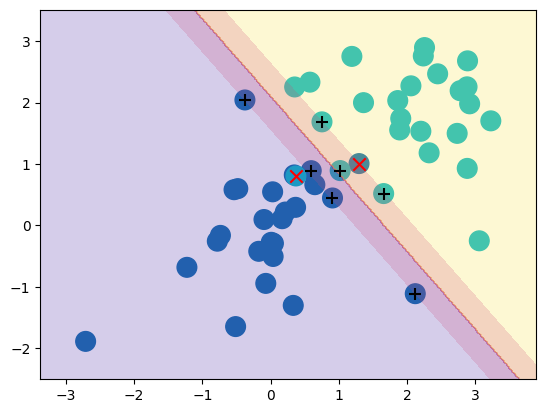

In [50]:
# Wykres modelu SVM: tło pokazuje obszary decyzyjne, a kontury — granicę i margines.
fig, ax = plt.subplots()
plot_svm_2d(X, y, svm_linear, ax=ax)
plt.show()

-----
##### *Zadanie 3*

Dla modelu z Zadania 2 narysuj samodzielnie, bez funkcji `plot_svm_2d`, prostą rozdzielającą klasy i wektory podpierające.

 a) Odczytaj wektor $w$ (atrybut `coef_`) i wyraz wolny $b$ (atrybut `intercept_`), a następnie wyznacz współczynniki $A$ i $B$ prostej rozdzielającej (wzory poniżej).

 b) Wyznacz, które punkty są wektorami podpierającymi.

 c) Narysuj punkty, prostą rozdzielającą dla $x_1 \in [-1.5, 3]$ oraz zaznacz wektory podpierające.

#### Wyznaczanie hiperpłaszczyzny (dla dwóch wymiarów)

$\langle w, x\rangle + b = 0$

$w_1x_1 + w_2x_2 + b = 0$

$w_2x_2 = -w_1x_1 - b$

$x_2 = -\frac{w_1}{w_2}x_1 - \frac{b}{w_2} = A x_1 + B$


In [51]:
# współczynniki z modelu i wyraz wolny
W = svm_linear.coef_[0]
b = svm_linear.intercept_[0]

# wyliczenie A i B
A = -W[0]/W[1]
B = -b/W[1]

In [52]:
# indeksy wektorów podpierających (support_) i odpowiadające im punkty
support = X[svm_linear.support_]
support

array([[ 0.90535587,  0.44637457],
       [ 1.29406381,  1.00672432],
       [ 2.11783876, -1.11202076],
       [-0.37760501,  2.04277161],
       [ 0.59374807,  0.89116695],
       [ 0.75125111,  1.68610053],
       [ 1.01781188,  0.89262695],
       [ 1.65478429,  0.51818173],
       [ 0.36915077,  0.80483692]])

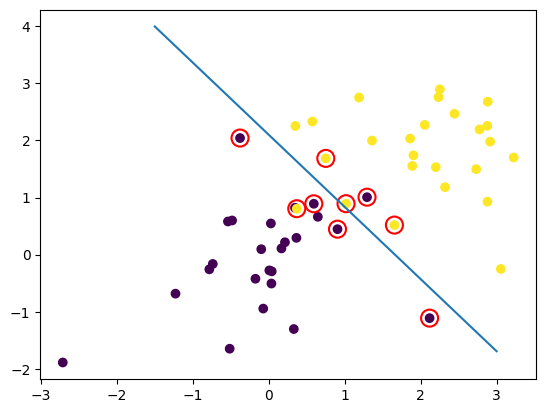

In [53]:
fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], c=y)
# prosta rozdzielająca
ax.plot(np.array([-1.5, 3]), A * np.array([-1.5, 3]) + B)
# wektory podpierające zaznaczamy czerwonymi okręgami
ax.scatter(support[:, 0], support[:, 1], s=150,
           facecolors='none', edgecolors='red', linewidths=1.5)
plt.show()

-----
##### *Zadanie 4*

Zbuduj model wektorów podpierających, wykorzystując zdefiniowane `X` i `y` jako zbiór treningowy. Ustaw parametr `C = 0.01` oraz `kernel = 'linear'`.

 a) Narysuj dopasowany model funkcją `plot_svm_2d`.

 b) Tak jak w Zadaniu 3 wyznacz współczynniki $A$ i $B$ prostej rozdzielającej.

 c) Wyznacz wektor jednostkowy $\hat{w}$ oraz szerokość marginesu $m$ (wzory poniżej).

 d) Narysuj punkty, prostą rozdzielającą oraz granice marginesu. Granice marginesu otrzymamy, przesuwając prostą rozdzielającą o $\pm\, m \hat{w}$ (kod poniżej).

#### Wyznaczanie marginesu (dla dwóch wymiarów)

$m = \frac{1}{\|w\|}$

$\|w\| = \sqrt{w_1^2 + w_2^2}$

$\hat{w} = \frac{w}{\|w\|}$


In [54]:
# model SVM, hiperparametry C i kernel
svm_linear_small = SVC(C=0.01, kernel='linear')
svm_linear_small.fit(X, y)

SVC(C=0.01, kernel='linear')

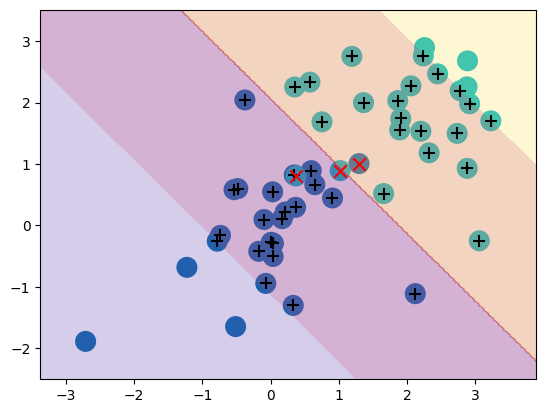

In [55]:
# Wykres modelu SVM dla mniejszej wartości C.
fig, ax = plt.subplots()
plot_svm_2d(X, y, svm_linear_small, ax=ax)
plt.show()

In [56]:
# wyznaczenie współczynników
W = svm_linear_small.coef_[0]
b = svm_linear_small.intercept_[0]

# wyznaczenie A i B prostej
A = -W[0]/W[1]
B = -b/W[1]

In [57]:
w_hat = svm_linear_small.coef_[0] / np.linalg.norm(svm_linear_small.coef_[0])

In [58]:
margin = 1 / np.linalg.norm(svm_linear_small.coef_[0])

In [59]:
decision_boundary_points = np.array(list(zip(np.array([-1.5, 3]), A * np.array([-1.5, 3]) + B)))
points_of_line_above = decision_boundary_points + w_hat * margin
points_of_line_below = decision_boundary_points - w_hat * margin

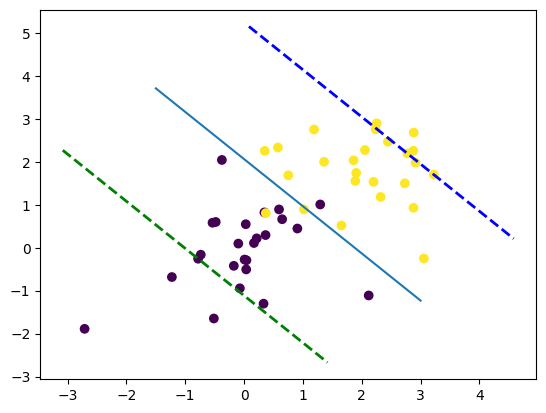

In [60]:
fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], c=y)
ax.plot(np.array([-1.5, 3]), A * np.array([-1.5, 3]) + B)
# granica marginesu po stronie klasy 1 (przesunięcie w kierunku w)
ax.plot(points_of_line_above[:, 0],
        points_of_line_above[:, 1],
        'b--',
        linewidth=2)
# granica marginesu po stronie klasy -1 (przesunięcie przeciwnie do w)
ax.plot(points_of_line_below[:, 0],
        points_of_line_below[:, 1],
        'g--',
        linewidth=2)
plt.show()

#### Optymalizacja parametru C z wykorzystaniem GridSearchCV


In [61]:
kfold = skm.StratifiedKFold(5,
                            random_state=0,
                            shuffle=True)

In [62]:
grid = skm.GridSearchCV(SVC(kernel='linear'),
                        {'C': [0.001, 0.01, 0.1, 1, 5, 10, 100]},
                        refit=True,  # dopasowanie modelu do całych danych treningowych po wybraniu optymalnych hiperparametrów
                        cv=kfold,  # informacje o strategii kroswalidacji
                        scoring='accuracy')

-----
##### *Zadanie 5*

 a) Dopasuj `grid` do danych `X`, `y`. Wypisz najlepsze hiperparametry (`best_params_`) i przedstaw wyniki walidacji krzyżowej (`cv_results_`) w postaci `DataFrame`, ograniczając się do wartości `C`, średniej i odchylenia standardowego dokładności oraz rankingu.

 b) Wygeneruj zbiór testowy (kod poniżej) i oceń na nim najlepszy model (`best_estimator_`): wyznacz macierz pomyłek i dokładność.


In [63]:
# dopasowanie modelu z różnymi hiperparametrami do danych
grid.fit(X, y)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=0, shuffle=True),
             estimator=SVC(kernel='linear'),
             param_grid={'C': [0.001, 0.01, 0.1, 1, 5, 10, 100]},
             scoring='accuracy')

In [64]:
# najlepsze hiperparametry
grid.best_params_

{'C': 0.01}

In [65]:
# wyniki walidacji krzyżowej: wartość C, średnia i odchylenie standardowe dokładności, ranking
pd.DataFrame(grid.cv_results_)[['param_C', 'mean_test_score', 'std_test_score', 'rank_test_score']]

,param_C,mean_test_score,std_test_score,rank_test_score
0,0.001,0.86,0.04899,7
1,0.010,0.96,0.04899,1
2,0.100,0.92,0.04000,6
3,1.000,0.94,0.04899,5
4,5.000,0.96,0.04899,1
5,10.000,0.96,0.04899,1
6,100.000,0.96,0.04899,1


**Komentarz.** Kilka wartości `C` (0.01, 5, 10 i 100) osiąga tę samą średnią dokładność 0.96. Przy remisie `GridSearchCV` wybiera pierwszą z tych wartości w kolejności siatki, dlatego `best_params_` wskazuje `C = 0.01` — nie oznacza to, że ta wartość jest wyraźnie lepsza od pozostałych. Na tak dobrze rozdzielonych danych wybór `C` ma niewielki wpływ na dokładność.


In [66]:
# zbiór testowy z tego samego rozkładu co dane treningowe
rng = np.random.default_rng(2)
X_test_svm = rng.standard_normal((20, 2))
y_test_svm = np.array([-1]*10 + [1]*10)
X_test_svm[y_test_svm == 1] += 2  # przesunięcie punktów z klasy 1 o [2, 2]

In [67]:
best_ = grid.best_estimator_  # najlepszy model, dopasowany ponownie do całych danych treningowych
y_pred_test = best_.predict(X_test_svm)  # predykcja na zbiorze testowym
confusion_matrix(y_test_svm, y_pred_test)  # macierz pomyłek

array([[9, 1],
       [1, 9]], dtype=int64)

In [68]:
# dokładność
accuracy_score(y_test_svm, y_pred_test)

0.9

### Podsumowanie, czyli co warto wiedzieć...

1. Elastic Net łączy regularyzację L1 i L2, a parametr `l1_ratio` określa ich proporcję.
2. Przygotowanie danych łączymy z modelem w `Pipeline`, aby transformacje były dopasowywane wyłącznie do danych uczących.
3. SVM szuka granicy rozdzielającej klasy o możliwie szerokim marginesie.
4. Wektory podpierające to obserwacje wyznaczające położenie tej granicy.
5. Parametr `C` określa kompromis między szerokim marginesem a liczbą błędów treningowych.
6. Hiperparametry dobieramy na zbiorze walidacyjnym lub walidacją krzyżową na danych treningowych — nigdy na zbiorze testowym.
